## Statistical Literacy II

We revisit our prediction task for October 16th, 2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

daily = pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\Data Science\data\wheather_daily.csv")
daily.date = pd.to_datetime(daily.date)
daily.head(3)

,Unnamed: 0,date,max_temperature,humidity,precipitation,pressure,wind_speed,month
0,0,2016-10-09,10.6,85.041667,1.4,1022.858333,9.729167,10
1,1,2016-10-10,11.7,81.208333,0.0,1023.716667,5.354167,10
2,2,2016-10-11,9.3,91.791667,3.3,1020.841667,9.466667,10


Many of you simply averaged the previous 10 temperatures on Oct 16th:

In [2]:
keepRows = (daily["date"].dt.month==10) & (daily["date"].dt.day==16)
historical = daily[keepRows]
forecast = historical["max_temperature"].mean()
print("Forecast for October 16, 2026:", round(forecast, 1), "°C")
historical.head(4)

Forecast for October 16, 2026: 14.9 °C


,Unnamed: 0,date,max_temperature,humidity,precipitation,pressure,wind_speed,month
7,7,2016-10-16,11.1,90.750000,0.1,1024.045833,10.016667,10
372,372,2017-10-16,21.5,82.125000,0.0,1022.333333,10.820833,10
737,737,2018-10-16,20.9,65.291667,0.0,1018.116667,5.200000,10
1102,1102,2019-10-16,14.5,92.958333,8.8,1008.237500,17.045833,10


## 1. Uncertainty

Clearly, there is large variation in those previous years.

Any self respecting forecast would not be content with just one number but would add a "plus minus":

*Forecast for October 16, 2026:* $14.7$ °C $\pm $ ___ °C

* Suggest metrics that express this uncertainty.
* What **exactly** do we mean by $\pm $ ?
* Might there be two different uncertainties involved?

#MSE = VARIANCE


In [16]:
#Standard Deviation (sigma) = 66% of publish_display_data
#Standard Error 
avg = 14.7
variance = np.array(daily.loc[daily["month"]==10, "max_temperature"])
variance_calc= np.sum((variance-variance.mean())**2)/np.count_nonzero(variance)
sigma=np.sqrt(variance_calc)
sigma_std = np.std(variance)
print(sigma_std)

3.6501456924667126


In [30]:
mean = historical["max_temperature"].mean()
_sigma = historical["max_temperature"].std()
SE = _sigma/np.sqrt(np.count_nonzero(historical["max_temperature"]))
SEˇo= np.sqrt(SE**2+_sigma**2)
print(mean, _sigma, SE, SEˇo)

14.86 4.365063318873825 1.380354221849514 4.578117031657835


---------------

## 2- Sample Size

We started out with almost 100K hourly data. Now we are left with **just 10 data points** (we call this our *sample size*) which we base our predictions on, isn't that a bit sad ?

* Suggest ways to use more data to obtain a forecast
* Identify a **critical tradeoff**.


In [11]:
print("Years available:", historical["max_temperature"].count())

Years available: 10


## 3 Bias-Variance Tradeoff

Recall our discussion on the "bin width" of histograms:

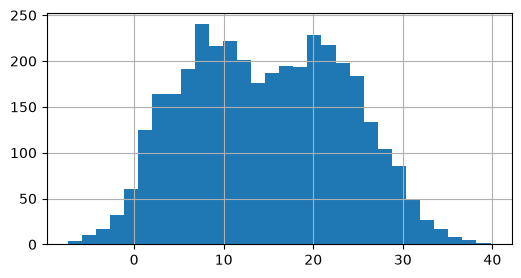

In [ ]:
daily.max_temperature.hist(bins=30, figsize=(6, 2.5));

In [33]:
#interactive version
#(you might have to install plotly: uv add plotly)
import plotly.express as px
from ipywidgets import interact, IntSlider

# Define the interactive function
@interact(bins=IntSlider(min=5, max=200, step=1, value=30,  continuous_update=False))
def update_histogram(bins):
    fig = px.histogram(daily, x="max_temperature", nbins=bins, height=300, width=600)
    fig.show()


ModuleNotFoundError: No module named 'plotly'

#### Discussion

* What is the effective sample size ?
* Describe the tradeoff
* How to
    * quantify the tradeoff
    * find the optimal bin width ?


---------------------------


### Simulations

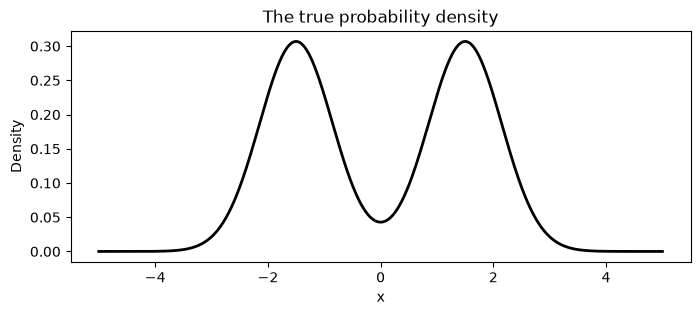

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

def sample_data_bimod1(n):
    component = rng.choice([0, 1], size=n)
    means = np.where(component == 0, -1.5, 1.5)
    return rng.normal(means, 0.65)
#how to make a bimodal sample?
def sample_data_bimod2(n):
    x1=rng.normal(1, 0.65 ,size= n/2 )
    x2=rng.normal(-1,0.65, size= n/2)
    return np.append(x1,x2)

def true_density(x):
    from scipy.stats import norm
    return 0.5 * norm.pdf(x, -1.5, 0.65) + \
           0.5 * norm.pdf(x,  1.5, 0.65)

x = np.linspace(-5, 5, 1000)
plt.figure(figsize=(8, 3))  # width=8 inches, height=3 inches
plt.plot(x, true_density(x), color="black", lw=2)
plt.title("The true probability density")
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

### Experiment A — change the bin width

Keep the data fixed and vary only the histogram bin width.

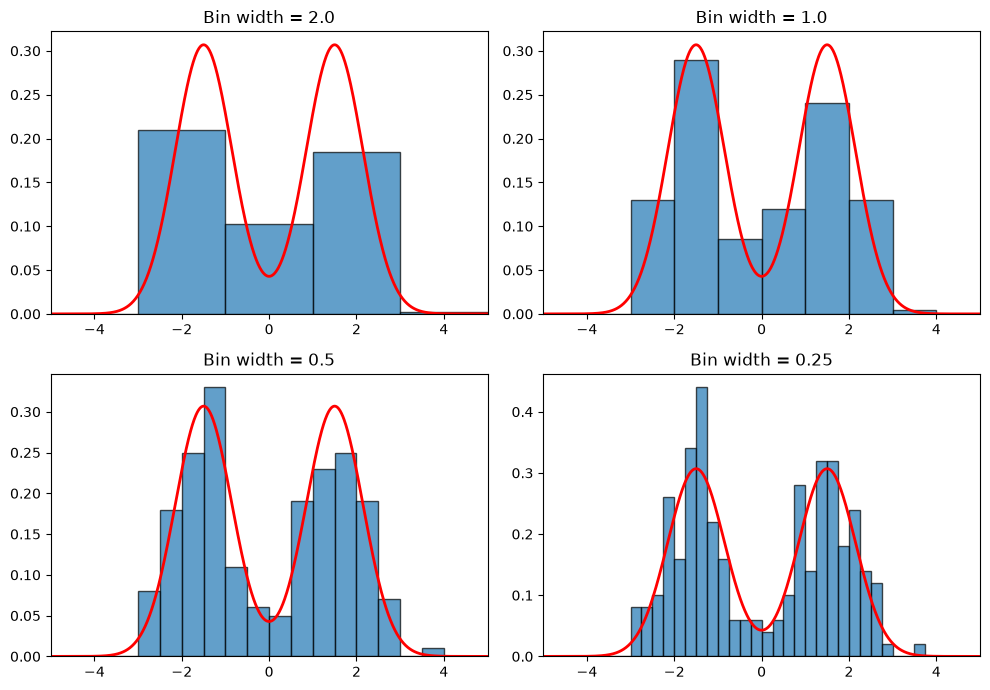

In [37]:
data = sample_data(200)
widths = [2.0, 1.0, 0.5, 0.25]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, width in zip(axes.flat, widths):
    ax.hist(data, bins=np.arange(-5, 5 + width, width),
            density=True, edgecolor="black", alpha=0.7)
    ax.plot(x, true_density(x), color="red", lw=2)
    ax.set_title(f"Bin width = {width}")
    ax.set_xlim(-5, 5)

plt.tight_layout()
plt.show()

### Experiment B — change the sample

This is the key experiment. A single histogram cannot demonstrate variance convincingly; we need to see what happens across repeated samples.

Keep the bin width fixed, and draw four independent samples from the same population.

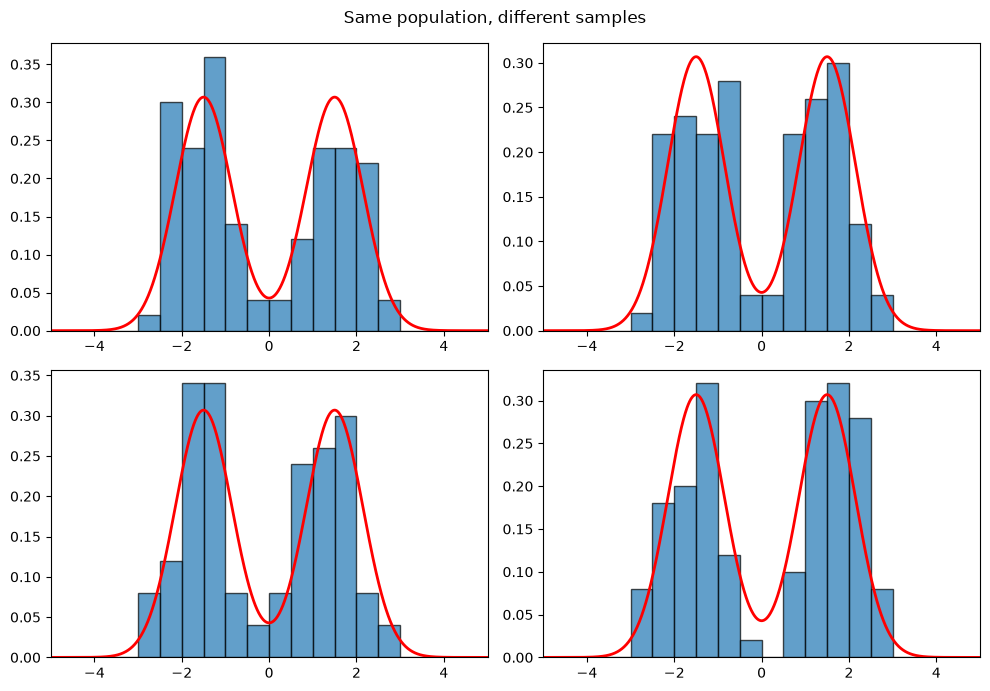

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax in axes.flat:
    data = sample_data(100)
    ax.hist(data, bins=np.arange(-5, 5.5, 0.5),
            density=True, edgecolor="black", alpha=0.7)
    ax.plot(x, true_density(x), color="red", lw=2)
    ax.set_xlim(-5, 5)

plt.suptitle("Same population, different samples")
plt.tight_layout()
plt.show()


- Which features remain stable across all four histograms?
- Which peaks or valleys change noticeably?
- What happens if we use narrower bins?

The narrower the bins, the more the histogram tends to respond to the particular observations in each sample. That is the visual intuition behind estimator variance.

-----------------

### Experiment C — quantify the bias–variance tradeoff

Now we move from visual intuition to a numerical result. For each bin width, generate many samples and measure how the histogram estimator behaves.

The important idea is to compare:
- Squared bias: how far the average histogram is from the true density.
- Variance: how much the histogram changes across repeated samples.
- Mean squared error (MSE): the combined error.

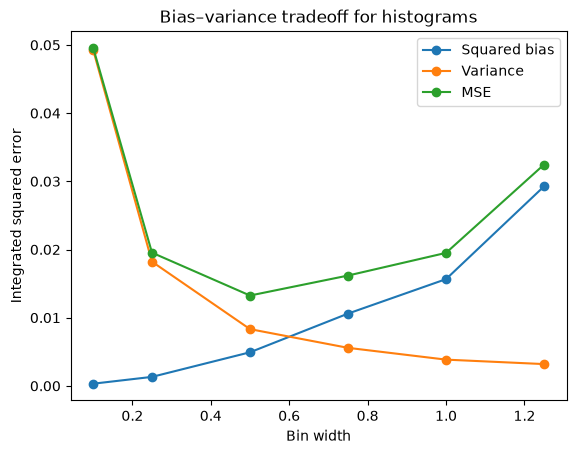

Width | Bias² | Variance | MSE
 1.25 | 0.0293 | 0.0032 | 0.0325
 1.00 | 0.0157 | 0.0039 | 0.0195
 0.75 | 0.0106 | 0.0056 | 0.0162
 0.50 | 0.0049 | 0.0083 | 0.0132
 0.25 | 0.0013 | 0.0182 | 0.0195
 0.10 | 0.0003 | 0.0493 | 0.0496


In [38]:
widths = [1.25, 1.0, 0.75, 0.5, 0.25, 0.1]
n_samples = 300
n = 200
dx = 0.025
grid = np.arange(-5 + dx/2, 5, dx)
truth = true_density(grid)

results = []

for width in widths:
    edges = np.arange(-5, 5 + width/2, width)
    estimates = []

    for _ in range(n_samples):
        data = sample_data(n)
        counts, _ = np.histogram(data, bins=edges)
        density = counts / (n * width)

        # Evaluate the histogram at each grid point
        estimate = np.zeros(len(grid))
        for i in range(len(density)):
            in_bin = (grid >= edges[i]) & (grid < edges[i + 1])
            estimate[in_bin] = density[i]
        estimates.append(estimate)

    estimates = np.array(estimates)
    average = estimates.mean(axis=0)

    bias_squared = np.mean((average - truth)**2) * 10
    variance = np.mean(estimates.var(axis=0)) * 10
    mse = np.mean(((estimates - truth)**2)) * 10

    results.append([width, bias_squared, variance, mse])

results = np.array(results)

plt.plot(results[:, 0], results[:, 1], "o-", label="Squared bias")
plt.plot(results[:, 0], results[:, 2], "o-", label="Variance")
plt.plot(results[:, 0], results[:, 3], "o-", label="MSE")

plt.xlabel("Bin width")
plt.ylabel("Integrated squared error")
plt.title("Bias–variance tradeoff for histograms")
plt.legend()
plt.show()

print("Width | Bias² | Variance | MSE")
for width, bias2, var, mse in results:
    print(f"{width:5.2f} | {bias2:.4f} | {var:.4f} | {mse:.4f}")